# Exploratory Data Analysis - Blinkit Dataset

## 1. Introduction

This project performs Exploratory Data Analysis (EDA) on the cleaned Blinkit dataset.

The analysis focuses on understanding sales patterns, product performance, customer ratings, delivery times, discounts, demand, and city-level sales.

## 2. Import Libraries

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 3. Load Cleaned Dataset

In [18]:
df = pd.read_csv("../data/Blinkit_Cleaned_Data.csv")

df.head()


,product_id,product_name,category,brand,price,discount_pct,final_price,rating,num_reviews,delivery_time_min,...,is_organic,packaging_type,weight_g,shelf_life_days,reorder_level,demand_index,date_added,expiry_date,offer_type,delivery_status
0,1,Tata Organic Grocery 300,Grocery,Tata,199.78,25,149.84,4.5,146,37,...,True,Can,750,212,15,73,2023-11-27,2024-06-26,No Offer,On-Time
1,2,Mother Dairy Lite Dairy 275,Dairy,Mother Dairy,44.32,30,31.02,4.0,264,36,...,False,Jar,1000,17,24,25,2024-08-07,2024-08-24,No Offer,Delayed
2,3,P&G Classic Personal 439,Personal Care,P&G,501.13,0,501.13,3.7,69,17,...,True,Jar,1000,1463,25,100,2024-03-03,2028-03-05,FreeDelivery,On-Time
3,4,Dettol Fresh Household 771,Household,Dettol,627.17,0,627.17,3.9,103,23,...,True,Bottle,200,1143,18,15,2024-08-07,2027-09-24,No Offer,On-Time
4,5,Minute Maid Daily Beverages 264,Beverages,Minute Maid,101.69,15,86.44,4.3,422,10,...,True,Can,300,363,30,6,2024-07-04,2025-07-02,No Offer,On-Time


## 4. Dataset Overview

This section examines the structure, size, columns, and basic statistical information of the dataset.

In [19]:
print("Rows and Columns:", df.shape)


Rows and Columns: (13000, 25)


In [20]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13000 entries, 0 to 12999
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   product_id         13000 non-null  int64  
 1   product_name       13000 non-null  object 
 2   category           13000 non-null  object 
 3   brand              13000 non-null  object 
 4   price              13000 non-null  float64
 5   discount_pct       13000 non-null  int64  
 6   final_price        13000 non-null  float64
 7   rating             13000 non-null  float64
 8   num_reviews        13000 non-null  int64  
 9   delivery_time_min  13000 non-null  int64  
 10  city               13000 non-null  object 
 11  seller             13000 non-null  object 
 12  stock              13000 non-null  int64  
 13  sold_quantity      13000 non-null  int64  
 14  profit_margin_pct  13000 non-null  float64
 15  is_organic         13000 non-null  bool   
 16  packaging_type     130

In [21]:
df.describe()


,product_id,price,discount_pct,final_price,rating,num_reviews,delivery_time_min,stock,sold_quantity,profit_margin_pct,weight_g,shelf_life_days,reorder_level,demand_index
count,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000
mean,6500.500000,267.303356,9.959231,240.735212,4.196931,255.000308,27.558769,110.140538,162.400077,22.652708,536.130769,397.555385,21.627769,43.380462
std,3752.921085,199.665148,8.575017,182.405552,0.475863,152.933513,7.139059,19.589137,132.742425,10.088389,406.997451,483.540218,3.928429,27.076935
min,1.000000,10.180000,0.000000,8.140000,2.500000,1.000000,10.000000,52.000000,0.000000,5.000000,100.000000,2.000000,10.000000,0.000000
25%,3250.750000,122.972500,0.000000,108.790000,3.900000,138.000000,23.000000,95.000000,54.000000,13.900000,250.000000,13.000000,19.000000,22.000000
50%,6500.500000,220.240000,10.000000,197.185000,4.200000,219.000000,27.000000,110.000000,120.000000,22.900000,400.000000,231.000000,22.000000,38.000000
75%,9750.250000,350.500000,15.000000,316.882500,4.500000,355.000000,32.000000,125.000000,253.000000,31.400000,750.000000,564.000000,25.000000,63.000000
max,13000.000000,999.930000,30.000000,998.920000,5.000000,1050.000000,56.000000,169.000000,720.000000,40.000000,2000.000000,1825.000000,33.000000,100.000000


## 5. Missing Value Analysis

This section checks the dataset for missing values to ensure data completeness.

In [22]:
df.isnull().sum()


product_id           0
product_name         0
category             0
brand                0
price                0
discount_pct         0
final_price          0
rating               0
num_reviews          0
delivery_time_min    0
city                 0
seller               0
stock                0
sold_quantity        0
profit_margin_pct    0
is_organic           0
packaging_type       0
weight_g             0
shelf_life_days      0
reorder_level        0
demand_index         0
date_added           0
expiry_date          0
offer_type           0
delivery_status      0
dtype: int64

In [23]:
print("Total missing values:", df.isnull().sum().sum())


Total missing values: 0


## 6. Duplicate Record Analysis

This section checks for duplicate records in the cleaned dataset.

In [24]:
print("Duplicate records:", df.duplicated().sum())


Duplicate records: 0


## 7. Statistical Analysis

Important statistics such as average price, average final price, average rating, average delivery time, total sold quantity, and average profit margin are calculated.

In [25]:
print("Average Price:", round(df["price"].mean(), 2))
print("Average Final Price:", round(df["final_price"].mean(), 2))
print("Average Rating:", round(df["rating"].mean(), 2))
print("Average Delivery Time:", round(df["delivery_time_min"].mean(), 2))
print("Total Sold Quantity:", df["sold_quantity"].sum())
print("Average Profit Margin:", round(df["profit_margin_pct"].mean(), 2))


Average Price: 267.3
Average Final Price: 240.74
Average Rating: 4.2
Average Delivery Time: 27.56
Total Sold Quantity: 2111201
Average Profit Margin: 22.65


## 8. Sales Analysis by Category

This section analyzes the total sold quantity across different product categories.

In [26]:
category_sales = (
    df.groupby("category")["sold_quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)


category
Bakery                 273416
Grocery                273006
Personal Care          270425
Dairy                  269516
Snacks                 262287
Fruits & Vegetables    260166
Beverages              254918
Household              247467
Name: sold_quantity, dtype: int64


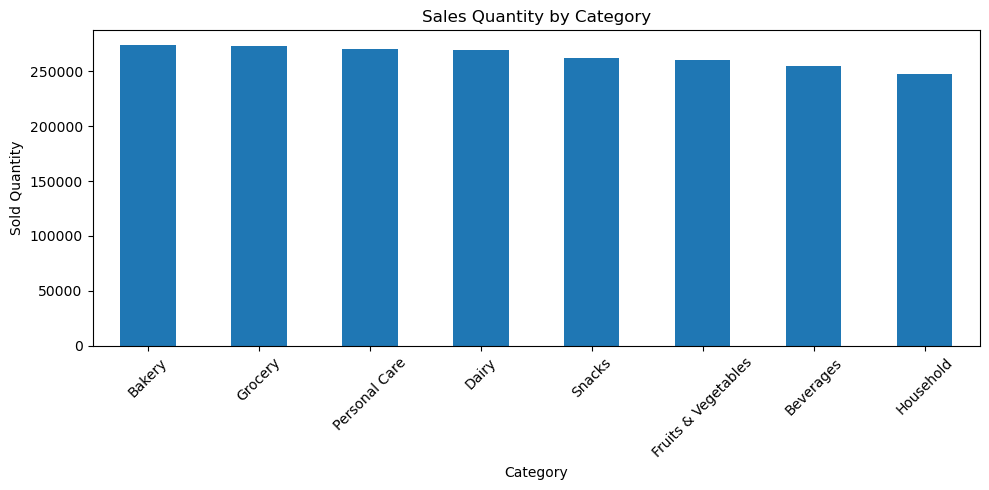

In [27]:
plt.figure(figsize=(10, 5))

category_sales.plot(kind="bar")

plt.title("Sales Quantity by Category")
plt.xlabel("Category")
plt.ylabel("Sold Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../charts/category_sales.png", dpi=300, bbox_inches="tight")
plt.show()


In [28]:
print("Top Selling Category:")
print(category_sales.head(1))


Top Selling Category:
category
Bakery    273416
Name: sold_quantity, dtype: int64


In [29]:
print("All Category Sales:")
print(category_sales)


All Category Sales:
category
Bakery                 273416
Grocery                273006
Personal Care          270425
Dairy                  269516
Snacks                 262287
Fruits & Vegetables    260166
Beverages              254918
Household              247467
Name: sold_quantity, dtype: int64


## 9. Sales Analysis by City

This section compares the total sold quantity across different cities.

In [30]:
city_sales = (
    df.groupby("city")["sold_quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(city_sales)


city
Mumbai       219930
Bengaluru    217651
Delhi        213243
Lucknow      212665
Pune         212110
Ahmedabad    211695
Jaipur       211135
Kolkata      211046
Hyderabad    205199
Chennai      196527
Name: sold_quantity, dtype: int64


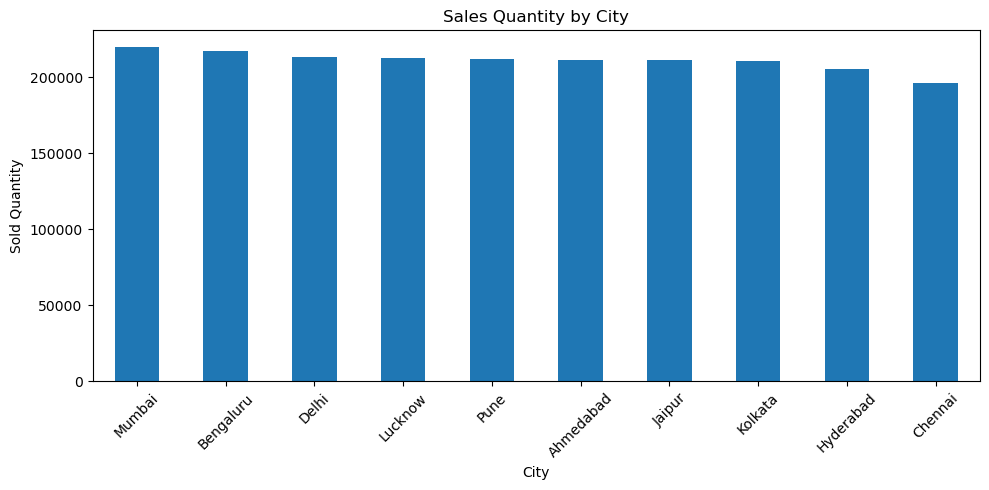

In [31]:
plt.figure(figsize=(10, 5))

city_sales.plot(kind="bar")

plt.title("Sales Quantity by City")
plt.xlabel("City")
plt.ylabel("Sold Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../charts/city_sales.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Product Rating Analysis

This section examines the distribution of product ratings in the dataset.

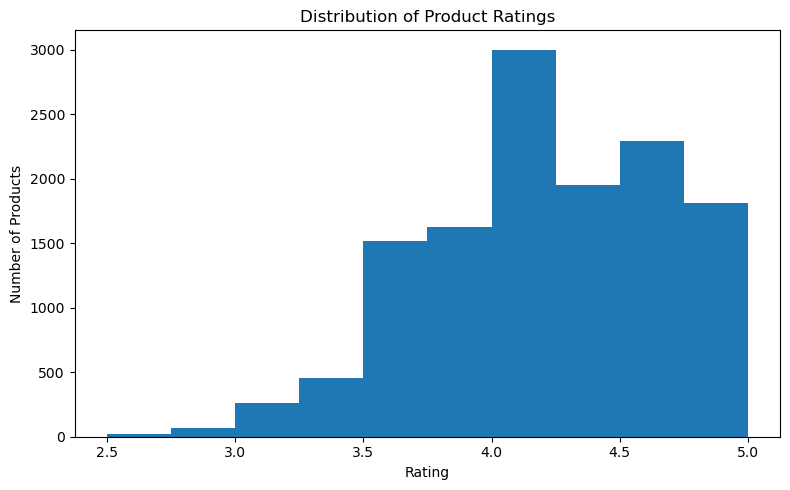

In [32]:
plt.figure(figsize=(8, 5))

df["rating"].plot(kind="hist", bins=10)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.savefig("../charts/rating_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## 11. Discount and Sales Analysis

This section explores the relationship between discount percentage and sold quantity.

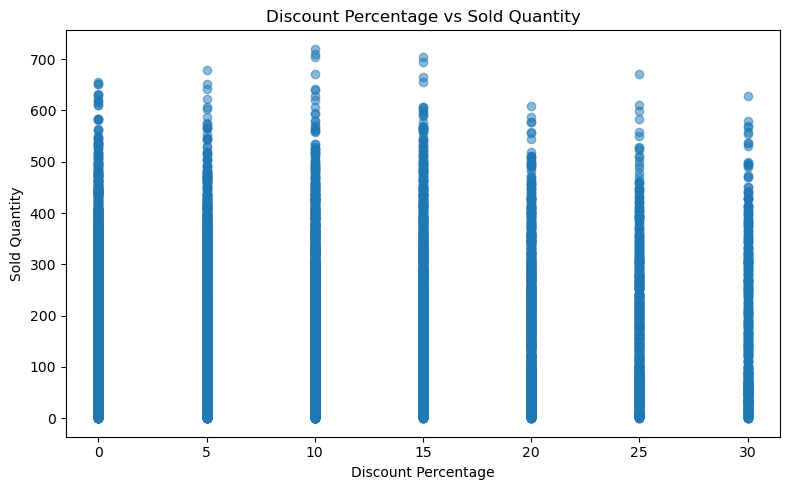

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["discount_pct"],
    df["sold_quantity"],
    alpha=0.5
)

plt.title("Discount Percentage vs Sold Quantity")
plt.xlabel("Discount Percentage")
plt.ylabel("Sold Quantity")
plt.tight_layout()
plt.savefig("../charts/discount_vs_sales.png", dpi=300, bbox_inches="tight")
plt.show()


## 12. Delivery Time Analysis

This section examines the distribution of delivery times across the dataset.

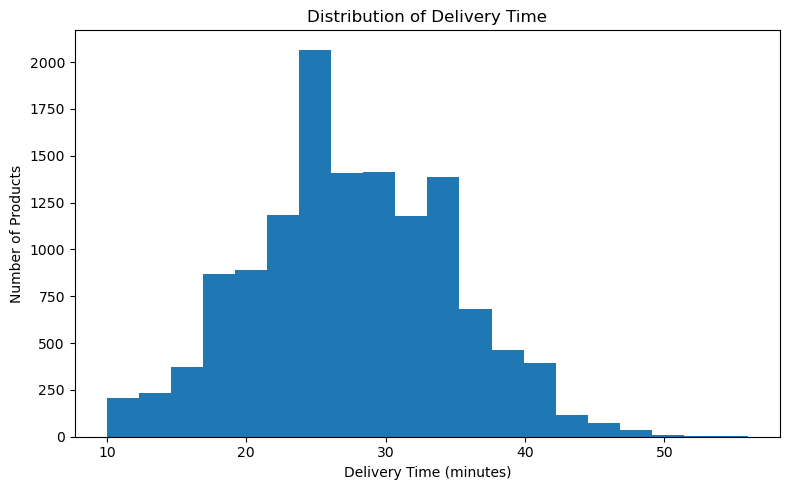

In [34]:
plt.figure(figsize=(8, 5))

df["delivery_time_min"].plot(kind="hist", bins=20)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.savefig("../charts/delivery_time_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## 13. Top 10 Best-Selling Products

This section identifies the top 10 products based on total sold quantity.

In [35]:
top_products = (
    df.groupby("product_name")["sold_quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)


product_name
Lizol Fresh Household 484        967
Harpic Organic Household 624     855
FreshFarm Organic Fruits 234     850
DailyGreens Organic Fruits 90    839
Britannia Classic Bakery 398     824
DailyGreens Daily Fruits 776     811
Gowardhan Organic Dairy 728      787
Amul Organic Dairy 776           778
Himalaya Premium Personal 934    768
Parle Premium Snacks 746         720
Name: sold_quantity, dtype: int64


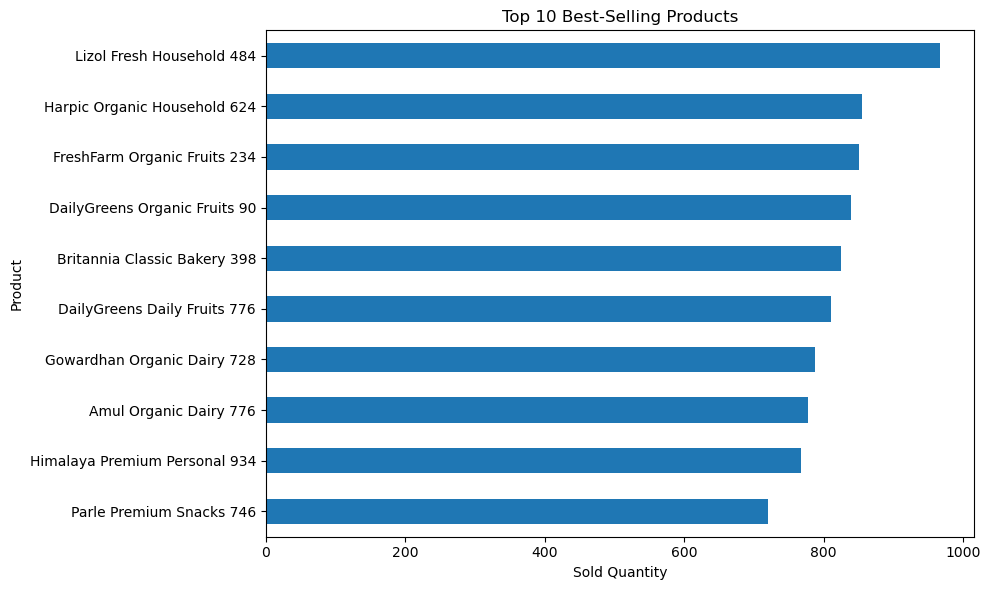

In [36]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Sold Quantity")
plt.ylabel("Product")

plt.tight_layout()
plt.savefig("../charts/top_10_products.png", dpi=300, bbox_inches="tight")
plt.show()


## 14. Stock and Demand Analysis

This section explores the relationship between stock levels and demand index.

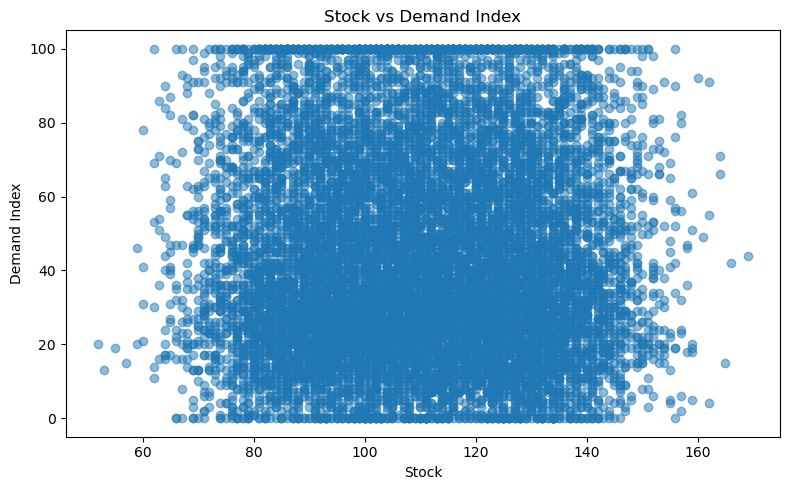

In [37]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["stock"],
    df["demand_index"],
    alpha=0.5
)

plt.title("Stock vs Demand Index")
plt.xlabel("Stock")
plt.ylabel("Demand Index")

plt.tight_layout()
plt.savefig("../charts/stock_vs_demand.png", dpi=300, bbox_inches="tight")
plt.show()


In [38]:
print("Top 5 Categories:")
print(category_sales.head(5))


Top 5 Categories:
category
Bakery           273416
Grocery          273006
Personal Care    270425
Dairy            269516
Snacks           262287
Name: sold_quantity, dtype: int64


In [39]:
print("\nTop 5 Cities:")
print(city_sales.head(5))



Top 5 Cities:
city
Mumbai       219930
Bengaluru    217651
Delhi        213243
Lucknow      212665
Pune         212110
Name: sold_quantity, dtype: int64


In [40]:
print("\nTop 10 Products:")
print(top_products)



Top 10 Products:
product_name
Lizol Fresh Household 484        967
Harpic Organic Household 624     855
FreshFarm Organic Fruits 234     850
DailyGreens Organic Fruits 90    839
Britannia Classic Bakery 398     824
DailyGreens Daily Fruits 776     811
Gowardhan Organic Dairy 728      787
Amul Organic Dairy 776           778
Himalaya Premium Personal 934    768
Parle Premium Snacks 746         720
Name: sold_quantity, dtype: int64


In [41]:
print("\nHighest Demand Products:")
print(
    df.nlargest(10, "demand_index")
    [["product_name", "demand_index", "stock"]]
)



Highest Demand Products:
                         product_name  demand_index  stock
2            P&G Classic Personal 439           100    126
13   Britannia Family Pack Bakery 876           100     92
56           Parle Organic Snacks 640           100    113
59    Lizol Family Pack Household 174           100    129
86          Dove Premium Personal 235           100     89
119              ITC Fresh Snacks 859           100    107
148       Gowardhan Organic Dairy 886           100     93
169         Britannia Lite Snacks 492           100     87
210      Dettol Classic Household 616           100    102
221           Modern Daily Bakery 447           100     97


## 15. Key EDA Insights

The analysis helps identify important trends, patterns, and observations from the Blinkit dataset.

1. **Category Sales:** Bakery recorded the highest total sold quantity with 273,416 units, followed by Grocery with 273,006 units.

2. **City Sales:** Mumbai recorded the highest total sold quantity with 219,930 units, followed by Bengaluru with 217,651 units.

3. **Product Sales:** The highest-selling product name was Lizol Fresh Household 484 with 967 units sold.

4. **Product Ratings:** The average product rating was 4.20, indicating generally positive customer ratings across the dataset.

5. **Delivery Performance:** The average delivery time was 27.56 minutes, while delivery times ranged from 10 to 56 minutes.

6. **Profitability:** The average profit margin was 22.65%, showing the overall average profitability level in the dataset.

7. **Demand:** Several products recorded a demand index of 100, representing the highest demand level observed in the dataset.

## 16. Conclusion

The exploratory data analysis provided useful insights into product sales, category performance, city-level sales, ratings, discounts, delivery times, stock levels, and demand.

The findings can be used to better understand sales patterns and support data-driven business decisions.